# 02 QNN y Variational Quantum Classifier

El circuito entero como modelo: mapa de características + ansatz entrenable + observable medido. Mismo iris difícil del cuaderno 01, para comparar kernel fijo contra circuito entrenable.

Referencias: handbook ([QNNs](https://iraitzm.github.io/qc-handbook/es/parts/qml/qnns.html), ejemplo `qnnexample.ipynb`) y [encoding circuits de sQUlearn](https://squlearn.github.io/user_guide/encoding_circuits.html).


In [1]:
!pip install -q squlearn scikit-learn matplotlib pylatexenc


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. Datos: el split difícil (versicolor vs virginica)

Etiquetas 1/2 tal cual: el clasificador de sQUlearn las acepta directamente.


In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data[iris.target > 0][:, :2]
Y = iris.target[iris.target > 0] - 1  # clases 0/1: SquaredLoss lo exige

X_train, X_test, y_train, y_test = train_test_split(
    MinMaxScaler().fit_transform(X), Y, test_size=0.33, random_state=42)
print('train:', X_train.shape, 'test:', X_test.shape)

train: (67, 2) test: (33, 2)


## 2. Feature map: YZ_CX de sQUlearn

Mapa con entrelazamiento CNOT listo para usar (ver cuaderno 01 para el porqué del mapa).


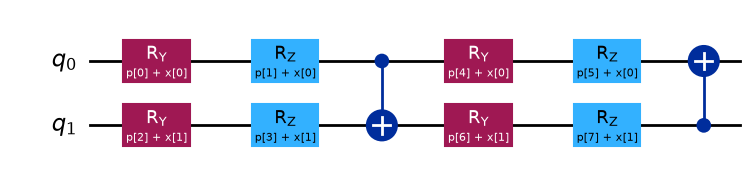

In [3]:
from squlearn.encoding_circuit import YZ_CX_EncodingCircuit

num_features = X_train.shape[1]
feature_map = YZ_CX_EncodingCircuit(num_qubits=num_features, num_features=num_features, num_layers=2)
feature_map.draw('mpl', num_features=num_features)

## 3. Ansatz: capas Ry + entrelazado a medida

Circuito totalmente parametrizado (sin datos): aquí viven los pesos que Adam ajustará.


In [ ]:
from squlearn.encoding_circuit import LayeredEncodingCircuit
from squlearn.encoding_circuit.layered_encoding_circuit import Layer

ansatz = LayeredEncodingCircuit(num_qubits=num_features, num_features=num_features)
layer = Layer(ansatz)
layer.Ry('p')
layer.cx_entangling('NN')
ansatz.add_layer(layer, num_layers=1)
ansatz.draw('mpl', style='clifford')

# sQUlearn >= 0.12 exige inicializar los PQC por capas antes de ajustar
ansatz.generate_initial_parameters(num_features=num_features, seed=0)
feature_map.generate_initial_parameters(num_features=num_features, seed=0)

array([ 0.30670429,  1.35207467,  0.64568133,  0.28200936, -0.47969104,
        0.91667975, -0.39215112,  2.46158236])

## 4. Estructura + observable

$f(x,\theta) = \langle \Psi(x,\theta) | O | \Psi(x,\theta) \rangle$. Un solo $Z$ basta para binaria (devuelve $\pm 1$).


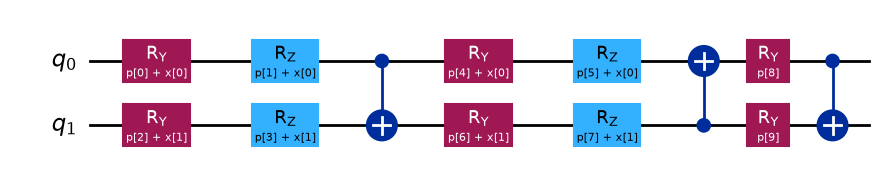

In [5]:
qnn_structure = feature_map + ansatz
qnn_structure.draw('mpl', num_features=num_features)

In [6]:
from squlearn.observables import CustomObservable

observable = CustomObservable(num_qubits=num_features, operator_string='I' * (num_features - 1) + 'Z', parameterized=True)
print(observable)

(p[0]) * IZ


## 5. Entrenar el VQC

`QNNClassifier` + `SquaredLoss` + `Adam`: la misma llamada `.fit` que en scikit-learn.


In [7]:
from squlearn.qnn import QNNClassifier, SquaredLoss
from squlearn.optimizers import SLSQP
from squlearn import Executor

qnn = QNNClassifier(qnn_structure, observable, Executor('statevector_simulator'), SquaredLoss(), SLSQP(options={'maxiter': 50}))
qnn.fit(X_train, y_train)
print('VQC train:', round(qnn.score(X_train, y_train), 3))
print('VQC test: ', round(qnn.score(X_test, y_test), 3))

fit: 100%|██████████| 50/50 [01:13<00:00,  1.48s/it]
VQC train: 0.761
VQC test:  0.727


## 6. Comparar contra el kernel fijo

Mismo split difícil: QSVM con ZZ (cuaderno 01) frente a VQC entrenado. ¿Compensa entrenar el circuito?


In [8]:
from sklearn.metrics import classification_report

print(classification_report(y_test, qnn.predict(X_test)))

              precision    recall  f1-score   support

           0       0.75      0.79      0.77        19
           1       0.69      0.64      0.67        14

    accuracy                           0.73        33
   macro avg       0.72      0.72      0.72        33
weighted avg       0.73      0.73      0.73        33



## 7. Catálogo de mapas en una línea (puente al cuaderno 03)

Los mismos PQC sirven como codificadores del reservorio: cambiad el mapa, no el código.


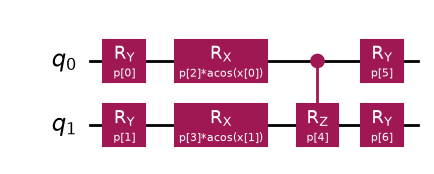

In [9]:
from squlearn.encoding_circuit import ChebyshevPQC, HubregtsenEncodingCircuit

ChebyshevPQC(num_qubits=2, num_features=2, num_layers=1).draw('mpl')

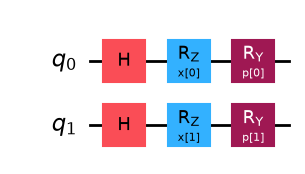

In [10]:
HubregtsenEncodingCircuit(num_qubits=2, num_features=2, num_layers=1).draw(output='mpl')

## Para clase

- Tarea: subid `num_layers` del ansatz a 2 y comparad train/test (¿sobreajuste?).
- Tarea: probad el observable sobre el otro qubit o `data re-uploading` (mapa con `num_layers=2` ya lo insinúa).
